# 02 · Detección difusa del régimen de mercado (Bloque 1)

Indicadores causales → sistema de lógica difusa → 4 probabilidades que suman 1.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt

from athenai.config import load_config
from athenai.data.build import load_processed
from athenai.pipeline import run_regimes
from athenai.regimes.fuzzy import REGIMES
from athenai.viz import style as S

S.set_style()
cfg = load_config()
proc = load_processed(cfg)
reg = run_regimes(cfg, proc)

C:\Users\ferju\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ferju\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\ferju\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\ferju\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 969, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ferju\AppData\Local\Programs\Python\Python

## Reglas en lenguaje natural

In [2]:
for r in reg["fuzzy"].rules_text():
    print("•", r)

• SI la tendencia es positiva Y la volatilidad es baja ENTONCES alcista
• SI la tendencia es positiva Y la amplitud es fuerte ENTONCES alcista
• SI la tendencia es negativa Y la amplitud es débil ENTONCES bajista
• SI la tendencia es negativa Y la volatilidad es media ENTONCES bajista
• SI la tendencia es neutra Y la volatilidad es baja ENTONCES lateral
• SI la tendencia es neutra Y el drawdown es pequeño ENTONCES lateral
• SI la volatilidad es alta Y el drawdown es grande ENTONCES crisis
• SI la volatilidad es alta Y la tendencia es negativa ENTONCES crisis


## Las probabilidades suman 1 (requisito del enunciado)

In [3]:
proba = reg["proba"]
print("Suma de P(fase) por fila — min:", proba[REGIMES].sum(1).min(),
      " max:", proba[REGIMES].sum(1).max())
proba.head()

Suma de P(fase) por fila — min: 0.9999999999999998  max: 1.0000000000000002


,alcista,bajista,lateral,crisis
date,,,,
2020-06-01,0.0,0.0,1.0,0.0
2020-06-02,0.0,0.0,1.0,0.0
2020-06-03,0.0,0.0,1.0,0.0
2020-06-04,0.0,0.0,1.0,0.0
2020-06-05,0.0,0.0,1.0,0.0


## Distribución de fases y comparación con baselines interpretables

In [4]:
print("Distribución de la fase dominante (%):")
print((reg["dominant"].value_counts(normalize=True) * 100).round(1))
print(f"\nCoincidencia difuso vs umbrales: {reg['agreement_threshold']*100:.1f}%")
print(f"Coincidencia difuso vs k-means : {reg['agreement_kmeans']*100:.1f}%")

Distribución de la fase dominante (%):
regime
lateral    38.4
alcista    24.2
crisis     23.9
bajista    13.6
Name: proportion, dtype: float64

Coincidencia difuso vs umbrales: 64.2%
Coincidencia difuso vs k-means : 54.3%


## Probabilidades de fase en el tiempo (área apilada)

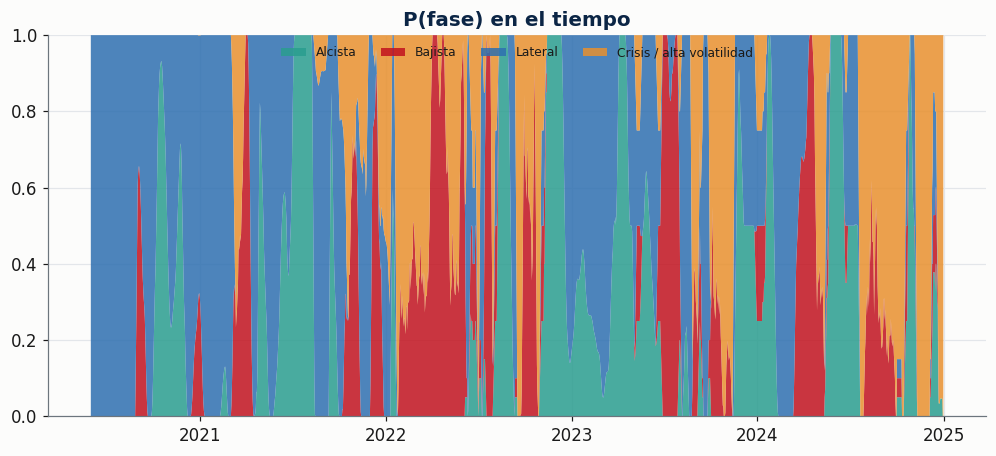

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.stackplot(proba.index, [proba[r] for r in REGIMES],
             colors=[S.REGIME_COLORS[r] for r in REGIMES],
             labels=[S.REGIME_LABELS[r] for r in REGIMES], alpha=0.85)
ax.set_ylim(0, 1)
ax.set_title("P(fase) en el tiempo")
ax.legend(loc="upper center", ncol=4, fontsize=8)
plt.show()